![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluation and Interpretation

*Project 2 — Machine Learning: From Data to Predictions*

**Team: Zoé Doucet**
**Dataset: Covertype**

---

Notebook 03_evaluation_and_interpretation focuses on evaluating and interpreting the final model. Its performance is assessed  and compared with other models. Finally, the selected model is saved for future use.

---
## 0. Setup and loading the data

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score, classification_report, ConfusionMatrixDisplay)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from matplotlib.patches import Patch

from src.functions import *

pd.set_option("display.max_columns", 100)


To load the data, execute the following cell. The detailed process of preparing, processing, and cleaning the data can be found in Sections 2 and 6 of the notebook [01_eda_and_baseline](01_eda_and_baseline.ipynb).

In [2]:
covertype = prepare_covertype_data() # loading the data

File already exists: ..\data\covertype_clean.csv. Loading existing dataset.


In [3]:
# dictionary with the names of the cover types
cover_type_names = {
    1: "Spruce and Fir",
    2: "Lodgepole Pine",
    3: "Ponderosa Pine",
    4: "Cottonwood and Willow",
    5: "Aspen",
    6: "Douglas-fir",
    7: "Krummholz"}

---
## 1. The question and the final model

The goal of the project is to build a machine learning classification model that can **predict a forest cover type** based on these cartographic variables. The model could help anticipate which type of forest is likely to occur in a given area. The **target** variable is the forest **covertype**, while the remaining variables serve as input features. To evaluate its performance, accuracy and recall will be used. **Accuracy** measures the overall proportion of correct predictions, while **recall** measures how effectively the model identifies each forest covertype. Particular attention was be paid to misclassified observations to identify where the model struggles and how its classification performance could be improved.

The final model selected was a Random Forest Classifier, using a StandardScaler for numerical features and one-hot encoding for categorical features in the preprocessing pipeline. The model uses the following hyperparameters:

- max_depth=None
- min_samples_leaf=1
- n_estimators=300

The classification threshold was kept at the default value of 0.5.

The detailed model chosing process can be found in notebook [02_pipelines_and_models](02_pipelines_and_models.ipynb).

In [4]:
# Splitting and training the data
X, y, X_train, X_test, y_train, y_test, cv, folds = split( covertype.drop(columns= ["cover_type"]),
                                                    covertype["cover_type"],
                                                    0.25,
                                                    42,
                                                    5)

435759 training rows, 145253 test rows


In [5]:
# preprocess
cat_features = ["soil_type", "wilderness_area"] # creating a list with the categorical features
num_features = X.drop(columns = cat_features).columns.tolist() # creating a list with the numerical features

preprocess = ColumnTransformer([
    ("num", 
      StandardScaler(), 
      num_features), # Scaling the numerical features
    ("cat", 
     OneHotEncoder(handle_unknown="ignore", sparse_output=False), 
     cat_features)])# transforming categrorical columns into binary columns

In [6]:
# final pipeline 
model_final = create_pipeline(preprocess,RandomForestClassifier(max_depth=None, n_estimators=300, random_state=42, n_jobs=-1, min_samples_leaf=1))

In [7]:
# training the model
model_final.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](7,)","[1,2,3,...,5,6,7]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['elevation','aspect','slope',...,'horizontal_distance_to_fire_points', 'soil_type','wilderness_area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (defau

---
## 2. Testing the final model once

The final model is tested once and the scores compared with the baseline and cross validation scores from the random forest model. The scores from the baseline can be found in notebook [01_eda_and_baseline](01_eda_and_baseline.ipynb) in section 10 and the scores of the random forest model can be found in notebook [02_pipelines_and_models](02_pipelines_and_models.ipynb) in section 5. 

In [8]:
# baseline scores
baseline_scores = {
        "f1": 0.094,
        "recall": 0.143,
        "accuracy": 0.488,
        "precision": 0.07}

In [9]:
# training model scores
radm_frst_scores = {
        "f1": 0.916,
        "recall": 0.897,
        "accuracy": 0.950,
        "precision": 0.940}

In [10]:
# test model
y_pred = model_final.predict(X_test)
test_scores = {
    "f1": round(f1_score(y_test, y_pred, average="macro"),3),
    "recall": round(recall_score(y_test, y_pred, average="macro"),3),
    "accuracy": round(accuracy_score(y_test, y_pred),3),
    "precision": round(precision_score(y_test, y_pred, average="macro"),3)}

print(test_scores)

{'f1': 0.924, 'recall': 0.905, 'accuracy': 0.954, 'precision': 0.946}


In [11]:
# comparing the models
scores_comparison = pd.DataFrame({
    "Baseline": baseline_scores,
    "Cross-validation": radm_frst_scores,
    "Test": test_scores}).T
print(scores_comparison)

                     f1  recall  accuracy  precision
Baseline          0.094   0.143     0.488      0.070
Cross-validation  0.916   0.897     0.950      0.940
Test              0.924   0.905     0.954      0.946


The **final model performs well on the test set**, as it has the highest scores. It achieves an **F1 score of 0.924** and an **accuracy of 0.954**. These results are very close to the cross validation scores from the random forest model, but they are slightly higher. This suggests that the model generalizes well to unseen data. The baseline has the lowest scores, particularly F1 and precision are very low compared to the Random Forest Model.

---
## 3. Confusion matrix

The confusion matrix shows in which cases the models predictions are wrong. The threshold was kept a the default value of 0.5 because lowering the threshold came at the cost of slightly lower precision and more false positives. The default threshold was therefore considered a reasonable balance between precision and recall.

              precision    recall  f1-score   support

           1      0.964     0.942     0.953     52960
           2      0.948     0.973     0.961     70825
           3      0.940     0.959     0.950      8938
           4      0.916     0.844     0.879       687
           5      0.949     0.769     0.849      2373
           6      0.929     0.900     0.914      4342
           7      0.975     0.948     0.961      5128

    accuracy                          0.954    145253
   macro avg      0.946     0.905     0.924    145253
weighted avg      0.954     0.954     0.954    145253



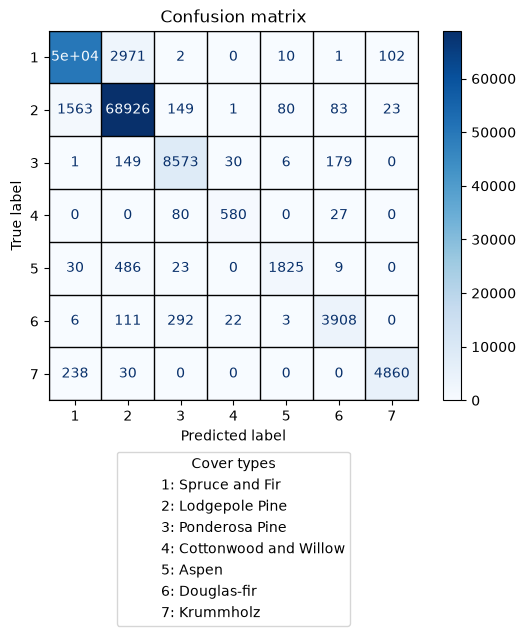

In [12]:
print(classification_report(y_test, y_pred, digits=3))

# Confusion matrix
disp = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation="horizontal", cmap="Blues")

ax = disp.ax_
n = len(disp.display_labels)
ax.grid(False, which="both")
ax.set_title("Confusion matrix")
ax.set_xticks(np.arange(n + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(n + 1) - 0.5, minor=True)
ax.grid(which="minor", color="black", linestyle="-", linewidth=1)
ax.tick_params(which="minor", bottom=False, left=False)

legend_handles = [Patch(facecolor="none", edgecolor="none",label=f"{label}: {name}")
          for label, name in cover_type_names.items()]
ax.legend(handles=legend_handles, title="Cover types", loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=True)

plt.show()

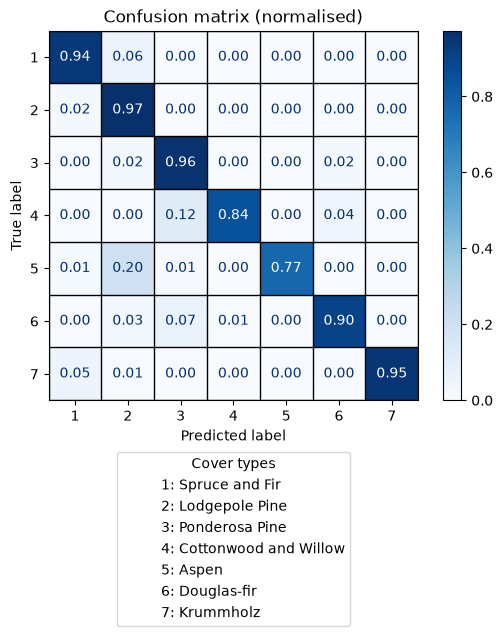

In [13]:
# Confusion matrix normalised
disp = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation="horizontal", cmap="Blues", normalize= "true", values_format=".2f")

ax = disp.ax_
n = len(disp.display_labels)
ax.grid(False, which="both")
ax.set_title("Confusion matrix (normalised)")
ax.set_xticks(np.arange(n + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(n + 1) - 0.5, minor=True)
ax.grid(which="minor", color="black", linestyle="-", linewidth=1)
ax.tick_params(which="minor", bottom=False, left=False)

legend_handles = [Patch(facecolor="none", edgecolor="none",label=f"{label}: {name}")
          for label, name in cover_type_names.items()]
ax.legend(handles=legend_handles, title="Cover types", loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=True)

plt.show()

The confusion matrix shows that **most cover types are correctly classified**. Cover type 2 is correctly classified 97 % of the time and is mostly confused with cover type 1 (2 %). Cover type 4 is correctly predicted 84 % of the time and is often misclassified as cover type 3 (12 %). Cover type 5 has the lowest correct classification rate, at 77 %, and is misclassified as cover type 2 in 20 % of cases. Although this misclassification rate is relatively high, unfortunately, it could not be improved by adjusting the classification threshold. 

---
## 4. Permutation importance analysis

The permutation importance shows which features contribute most to the model’s predictive performance, measured by the drop in test macro F1 score when each feature is randomly shuffled. The larger the drop, the more important the feature.

c:\Users\zoed\anaconda3\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


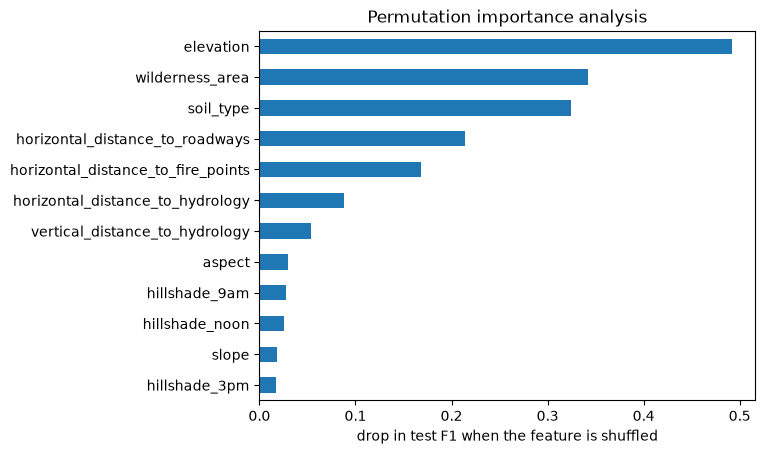

elevation                             0.492
wilderness_area                       0.342
soil_type                             0.324
horizontal_distance_to_roadways       0.214
horizontal_distance_to_fire_points    0.168
horizontal_distance_to_hydrology      0.088
vertical_distance_to_hydrology        0.053
aspect                                0.030
hillshade_9am                         0.028
hillshade_noon                        0.026
slope                                 0.019
hillshade_3pm                         0.017
dtype: float64

In [ ]:
perm = permutation_importance(model_final, X_test, y_test, scoring="f1_macro", n_repeats=20, random_state=0, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values()
importance.plot.barh()
plt.title("Permutation importance analysis")
plt.xlabel("drop in test F1 when the feature is shuffled")
plt.show()
importance.sort_values(ascending=False).round(3)

The permutation importance analysis, using macro F1 as the scoring metric, shows that elevation has the greatest influence on the model's predictions. Wilderness area, which indicates the location of the grid cell being evaluated, is the second most important feature. The least important features are hillshade at 3 p.m. and slope.

---
## 5. Save, reload, predict

In this section we will save, relaod the model and predict a few new samples.

In [ ]:
# saving the model
joblib.dump({"pipeline": model_final}, "../models/covertype_model.joblib")
print("Saved.")

Saved.


In [ ]:
saved = joblib.load("../models/covertype_model.joblib") #reloading the model
new_data = X_test.iloc[:5] # select two samples to predict

proba_new = saved["pipeline"].predict_proba(new_data)

# Getting the class with the highest probability for each row
predicted_indices = np.argmax(proba_new, axis=1)
predicted_classes = saved["pipeline"].classes_[predicted_indices]

# Printing the predicted class and its probability
for row, label, probs in zip(new_data.index, predicted_classes, proba_new):
    forest_type = cover_type_names[label]
    confidence = probs.max()
    print(f"Sample {row}: predicted forest type type {forest_type} with probability {confidence:.3f}")

Sample 101918: predicted forest type type Lodgepole Pine with probability 0.987
Sample 526334: predicted forest type type Lodgepole Pine with probability 0.970
Sample 142432: predicted forest type type Lodgepole Pine with probability 0.870
Sample 490937: predicted forest type type Lodgepole Pine with probability 0.617
Sample 447063: predicted forest type type Spruce and Fir with probability 0.980


The model performs well when predicting the new samples, with predicted probabilities above 0.8 for most samples. One sample has a lower probability of 0.617. This sample was classified as Lodgepole Pine (class 2), a forest cover type that the model often confuses with Aspen (class 5).

---
## 6. Conclusions and limitations

The final model can be useful for predicting forest cover types when only cartographic information is available and it is not possible to visit the location directly. This could be particularly useful in remote or inaccessible forests where a detailed vegetation map is not required. However, the model should not replace field surveys when precise information is needed.

There are also situations in which the model should be used with caution. For example, when identifying potentially protected forest types or assessing areas at risk of destruction, more detailed information may be necessary. In these cases, misclassifying a fragile or protected forest type could have serious consequences. The classification threshold could be adjusted to favour the detection of particularly important cover types, although this would need to be evaluated carefully.

One of the main limitations is that certain forest cover types are difficult to distinguish. This is particularly evident for Aspen (class 5), which the model sometimes confuses with Lodgepole Pine (class 2). One possible explanation is that these cover types share similar environmental characteristics. Furthermore, nature does not follow a predefined grid. Each observation represents a 30 × 30 metre cell assigned to a single cover type, even though multiple forest types may coexist within that area. This makes classification challenging, as the boundaries between forest types are not always clear-cut.

Another factor worth investigating is the role of geographical location. Including coordinates or more detailed spatial information might improve predictions by capturing geographical patterns in forest distribution. However, this would need to be tested to determine whether it genuinely improves the model's performance and generalisability.

If I had another week to work on this project, I would investigate additional environmental variables, such as temperature, wind exposure, and storm damage. These factors might help explain differences in the distribution of forest cover types and improve the model's ability to classify Aspen correctly.

Ultimately, this raises an important question: which environmental factors distinguish the growth conditions of Lodgepole Pine and Aspen, and is it even possible to separate these forest types clearly using cartographic data alone? Further investigation into this question could help determine whether the model's limitations stem primarily from the available data, the choice of features, or the natural overlap between forest types.